<a href="https://colab.research.google.com/github/MD-Zahid-Hasan-Tushar/zahid_H_project2/blob/main/Automatic_number_plate_recognition_(ANPR).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi


Sun Oct 11 20:28:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   63C    P0             30W /   70W |     253MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install easyocr
!pip install imutils

In [ ]:
import cv2
from matplotlib import pyplot as plt
import numpy as np
import imutils
import easyocr

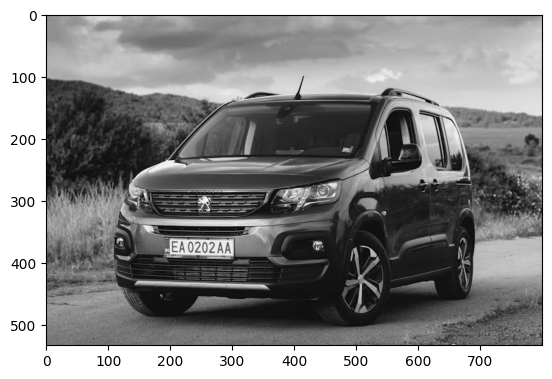

In [ ]:
img = cv2.imread('/content/photo-1687039588464-09f1b52208c7.avif')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
plt.imshow(cv2.cvtColor(gray, cv2.COLOR_BGR2RGB))

In [ ]:
from google.colab import drive
drive.mount('/c')

Drive already mounted at /c; to attempt to forcibly remount, call drive.mount("/c", force_remount=True).


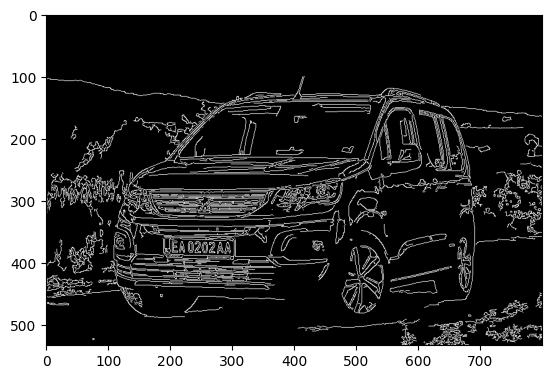

In [ ]:
bfilter= cv2.bilateralFilter(gray, 11, 17, 17) #Noise reduction DM sig
edged = cv2.Canny(bfilter, 30, 200) #Edge detection
plt.imshow(cv2.cvtColor(edged, cv2.COLOR_BGR2RGB))

In [ ]:
keypoints = cv2.findContours(edged.copy(), cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
contours = imutils.grab_contours(keypoints)
contours = sorted(contours, key=cv2.contourArea, reverse=True)[:10] # CDP to LPS

In [ ]:
location = None
for contour in contours:
    approx = cv2.approxPolyDP(contour, 10, True)
    if len(approx) == 4:
        location = approx
        break

In [ ]:
location

In [ ]:
if location is not None:
    mask = np.zeros(gray.shape, np.uint8)    #LR
    new_image = cv2.drawContours(mask, [location], 0, 255, -1)
    new_image = cv2.bitwise_and(img, img, mask=mask)
else:
    print("Error: License plate contour ('location') was not found in the image. Please adjust your edge detection thresholds or bilateral filter parameters.")

Error: License plate contour ('location') was not found in the image. Please adjust your edge detection thresholds or bilateral filter parameters.


In [ ]:
if 'new_image' in locals() or 'new_image' in globals():
    plt.imshow(cv2.cvtColor(new_image, cv2.COLOR_BGR2RGB))
else:
    print("Error: 'new_image' is not defined because the license plate contour detection step failed.")

Error: 'new_image' is not defined because the license plate contour detection step failed.


In [ ]:
(x,y) = np.where(mask==255)
(x1, y1) = (np.min(x), np.min(y))
(x2, y2) = (np.max(x), np.max(y))
cropped_image = gray[x1:x2+1, y1:y2+1]

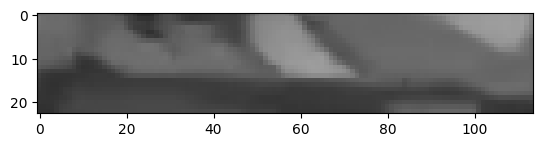

In [ ]:
plt.imshow(cv2.cvtColor(cropped_image, cv2.COLOR_BGR2RGB)) #ClPA

In [ ]:
reader = easyocr.Reader(['en'])
result = reader.readtext(cropped_image)
result

[]

In [ ]:
if len(result) > 0:
    text = result[0][-2]
    font = cv2.FONT_HERSHEY_SIMPLEX
    res = cv2.putText(img, text=text, org=(approx[0][0][0], approx[1][0][1]+60), fontFace=font, fontScale=1, color=(0,255,0), thickness=2, lineType=cv2.LINE_AA)
    res = cv2.rectangle(img, tuple(approx[0][0]), tuple(approx[2][0]), (0,255,0),3)
    plt.imshow(cv2.cvtColor(res, cv2.COLOR_BGR2RGB))
else:
    print("Error: No text was detected by EasyOCR, so 'result' is empty.")

Error: No text was detected by EasyOCR, so 'result' is empty.


In [ ]:
!pip install easyocr
!pip install torch torchvision
!pip install opencv-python imutils easyocr

In [ ]:
import cv2
import easyocr
import numpy as np
import imutils
from google.colab.patches import cv2_imshow
from IPython.display import HTML
from base64 import b64encode

# Initialize EasyOCR reader
reader = easyocr.Reader(['en'])

# Load video from file
video_path = "/content/car.mp4"  # Update with your input video file path
output_path = "/content/processed_video.mp4"  # Update with your desired output video file path
#ccontent/processed_video.mp4"  # Update with your desired output video file path

cap = cv2.VideoCapture(video_path)

# Check if video opened successfully
if not cap.isOpened():
    print("Error: Could not open video.")
    exit() # Dedent this line to align with the if statement

# Get video properties
fps = int(cap.get(cv2.CAP_PROP_FPS))
frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
frame_size = (frame_width, frame_height)

# Define the codec and create VideoWriter object
fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # Codec for .mp4 format
out = cv2.VideoWriter(output_path, fourcc, fps, frame_size)

frame_skip = 1  # Process every 3rd frame to improve performance
frame_count = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break

    frame_count += 1
    if frame_count % frame_skip != 0:
        continue

    # Resize frame for faster processing (optional)
    frame = imutils.resize(frame, width=800)
    resized_frame = cv2.resize(frame, frame_size)  # Resize back to original size for writing

    # Convert to grayscale
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # Noise reduction and edge detection
    bfilter = cv2.bilateralFilter(gray, 11, 17, 17)
    edged = cv2.Canny(bfilter, 30, 200)

    # Find contours
    keypoints = cv2.findContours(edged.copy(), cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    contours = imutils.grab_contours(keypoints)
    contours = sorted(contours, key=cv2.contourArea, reverse=True)[:10]

    location = None
    for contour in contours:
        approx = cv2.approxPolyDP(contour, 10, True)
        if len(approx) == 4:
            location = approx
            break

    if location is not None:
        # Create mask and extract license plate
        mask = np.zeros(gray.shape, np.uint8)
        cv2.drawContours(mask, [location], 0, 255, -1)
        (x, y) = np.where(mask == 255)
        (x1, y1) = (np.min(x), np.min(y))
        (x2, y2) = (np.max(x), np.max(y))
        cropped_image = gray[x1:x2+1, y1:y2+1]

        # OCR to read text
        result = reader.readtext(cropped_image)
        if result:
            text = result[0][-2]
            # Draw rectangle and text on the original frame
            cv2.putText(resized_frame, text, (location[0][0][0], location[0][0][1] - 10),
                                        cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)
            cv2.polylines(resized_frame, [location], isClosed=True, color=(0, 255, 0), thickness=2)

            # Write the frame to the output video
            out.write(resized_frame)

            # Optional: Display the frame (comment out if running in a non-GUI environment)
            # cv2.imshow('ANPR', resized_frame)
            # if cv2.waitKey(1) & 0xFF == ord('q'):
            #     break

# Release resources
cap.release()
out.release()
cv2.destroyAllWindows()

# Provide a link to download the processed video
def show_video(video_path, width=600):
    mp4 = open(video_path,'rb').read()
    data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
    return HTML(f'<video width={width} controls><source src="{data_url}" type="video/mp4"></video>')

show_video(output_path)